In [161]:
!pip install datasets

In [162]:
from datasets import load_dataset

dataset = load_dataset("dair-ai/emotion", "split")

In [163]:
import pandas as pd

train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

In [164]:
train_df.head()

,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3


In [165]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    16000 non-null  object
 1   label   16000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 250.1+ KB


In [166]:
label_map = {
    0: "Sadness",
    1: "Joy",
    2: "Love",
    3: "Anger",
    4: "Fear",
    5: "Surprise"
}

In [167]:
train_df["label"].value_counts()

,count
label,
1,5362
0,4666
3,2159
4,1937
2,1304
5,572


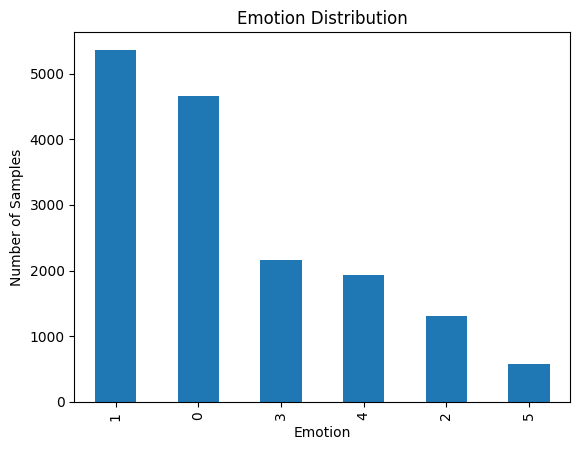

In [168]:
import matplotlib.pyplot as plt

train_df["label"].value_counts().plot(kind="bar")

plt.xlabel("Emotion")
plt.ylabel("Number of Samples")
plt.title("Emotion Distribution")
plt.show()

In [169]:
train_df["text"].head()

,text
0,i didnt feel humiliated
1,i can go from feeling so hopeless to so damned...
2,im grabbing a minute to post i feel greedy wrong
3,i am ever feeling nostalgic about the fireplac...
4,i am feeling grouchy


In [170]:
train_df["text"] = train_df["text"].str.lower()
val_df["text"] = val_df["text"].str.lower()
test_df["text"] = test_df["text"].str.lower()

In [171]:
import nltk
from nltk.tokenize import word_tokenize

nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [172]:

from nltk.tokenize import word_tokenize

train_df["text"] = train_df["text"].str.lower()

train_df["tokens"] = train_df["text"].apply(word_tokenize)

print(train_df[["text", "tokens"]].head())

                                                text  \
0                            i didnt feel humiliated   
1  i can go from feeling so hopeless to so damned...   
2   im grabbing a minute to post i feel greedy wrong   
3  i am ever feeling nostalgic about the fireplac...   
4                               i am feeling grouchy   

                                              tokens  
0                       [i, didnt, feel, humiliated]  
1  [i, can, go, from, feeling, so, hopeless, to, ...  
2  [im, grabbing, a, minute, to, post, i, feel, g...  
3  [i, am, ever, feeling, nostalgic, about, the, ...  
4                          [i, am, feeling, grouchy]  


In [173]:
from collections import Counter

word_freq = Counter()

for tokens in train_df["tokens"]:
    word_freq.update(tokens)

print(word_freq.most_common(10))

[('i', 25859), ('feel', 11183), ('and', 9589), ('to', 8972), ('the', 8370), ('a', 6200), ('feeling', 5112), ('that', 5112), ('of', 4990), ('my', 4283)]


In [174]:

vocab = {
    '<PAD>': 0,
    '<UNK>': 1
}

from collections import Counter
from nltk.tokenize import word_tokenize

word_freq = Counter()

# Collect words from ALL training sentences
for sent in train_df["text"]:
    word_freq.update(word_tokenize(sent.lower()))

# Build vocabulary from the complete word-frequency counter
for token in word_freq.keys():
    if token not in vocab:
        vocab[token] = len(vocab)

print("Vocabulary size:", len(vocab))



Vocabulary size: 15212


In [175]:
len(vocab)

15212

In [176]:
input=train_df['text'].str.split('/n')

In [177]:
def text_to_ind(sent, vocab):

    n_sent = []

    for token in sent:

        if token in vocab:
            n_sent.append(vocab[token])

        else:
            n_sent.append(vocab['<UNK>'])

    return n_sent


In [178]:

from nltk.tokenize import word_tokenize

def tokenize_text(sent):
    return word_tokenize(sent.lower())

word = text_to_ind(tokenize_text("I am angry"), vocab)

print(word)

[2, 31, 230]


In [179]:
training_seq=[]

for sent in train_df["text"]:
     training_seq.append(text_to_ind(word_tokenize(sent.lower()), vocab))



In [180]:
print(training_seq[:3])
print("Total sequences:", len(training_seq))

[[2, 3, 4, 5], [2, 6, 7, 8, 9, 10, 11, 12, 10, 13, 14, 15, 8, 16, 17, 18, 19, 20, 21, 22, 23], [24, 25, 26, 27, 12, 28, 2, 4, 29, 30]]
Total sequences: 16000


In [181]:
print(training_seq[0])
print(train_df["text"].iloc[0])
print(vocab["<PAD>"], vocab["<UNK>"])

[2, 3, 4, 5]
i didnt feel humiliated
0 1


In [182]:
import numpy as np

In [183]:
len_list=[]

for seq in training_seq:
  len_list.append(len(seq))



print("Maximum:", max(len_list))
print("95th percentile:", np.percentile(len_list, 95))


Maximum: 66
95th percentile: 41.0


In [184]:
max_len = int(np.percentile(len_list, 95))

In [185]:
padded_training_seq = []

for seq in training_seq:

    if len(seq) < max_len:
        padded_seq = seq + [0] * (max_len - len(seq))
    else:
        padded_seq = seq[:max_len]

    padded_training_seq.append(padded_seq)

In [186]:
print(padded_training_seq[0])
print(len(padded_training_seq[0]))
print(len(padded_training_seq))

[2, 3, 4, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
41
16000


In [187]:
import torch

X_train = torch.tensor(padded_training_seq, dtype=torch.long)

y_train = torch.tensor(
    train_df["label"].values,
    dtype=torch.long
)

print(X_train.shape)
print(y_train.shape)

torch.Size([16000, 41])
torch.Size([16000])


In [188]:
from torch.utils.data import Dataset

In [189]:
class EmotionDataset(Dataset):

    def __init__(self, X, y):
       self.X=X
       self.y=y


    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
       return self.X[idx], self.y[idx]

In [190]:
train_dataset = EmotionDataset(X_train, y_train)

print(train_dataset[0])

(tensor([2, 3, 4, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), tensor(0))


In [191]:
from torch.utils.data import DataLoader

In [192]:
train_loader=DataLoader(
    dataset=train_dataset,
    batch_size=32,
    shuffle=True
)

In [193]:
for X_batch, y_batch in train_loader:
    print("X shape:", X_batch.shape)
    print("y shape:", y_batch.shape)
    break

X shape: torch.Size([32, 41])
y shape: torch.Size([32])


In [194]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
class LSTM(nn.Module):

  def __init__(self,vocab_size,embedding_dim,hidden_size,num_classes):
    super().__init__()
    self.embedding=nn.Embedding(vocab_size,embedding_dim,padding_idx=0)
    self.lstm=nn.LSTM(embedding_dim,hidden_size,batch_first=True)
    self.fc=nn.Linear(hidden_size,num_classes)





  def forward(self,x):

    embedded = self.embedding(x)

    lengths = (x != 0).sum(dim=1).cpu()

    packed = pack_padded_sequence(
        embedded,
        lengths,
        batch_first=True,
        enforce_sorted=False
    )

    output, (hn,cn) = self.lstm(packed)

    final_hidden = hn[-1]

    logits = self.fc(final_hidden)

    return logits




In [195]:
vocab_size=len(vocab)
embedding_dim=100
hidden_size=128
num_classes=6


model=LSTM(
    vocab_size,embedding_dim,hidden_size,num_classes
)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [196]:
for X_batch, y_batch in train_loader:

    output = model(X_batch)

    print("Input shape:", X_batch.shape)
    print("Output shape:", output.shape)

    break

Input shape: torch.Size([32, 41])
Output shape: torch.Size([32, 6])


In [197]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [198]:
device

device(type='cuda')

In [199]:
model=model.to(device)

In [200]:

epochs = 10

for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for x, y in train_loader:

        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        output = model(x)

        loss = criterion(output, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        # Calculate accuracy for this batch
        predicted = torch.argmax(output, dim=1)

        correct += (predicted == y).sum().item()
        total += y.size(0)

    # Calculate epoch-level metrics
    avg_loss = total_loss / len(train_loader)
    accuracy = 100 * correct / total

    print(
        f"Epoch {epoch+1}/{epochs}, "
        f"Loss: {avg_loss:.4f}, "
        f"Accuracy: {accuracy:.2f}%"
    )


Epoch 1/10, Loss: 1.4706, Accuracy: 41.59%
Epoch 2/10, Loss: 0.8135, Accuracy: 72.26%
Epoch 3/10, Loss: 0.4008, Accuracy: 86.05%
Epoch 4/10, Loss: 0.2140, Accuracy: 92.41%
Epoch 5/10, Loss: 0.1352, Accuracy: 95.11%
Epoch 6/10, Loss: 0.0906, Accuracy: 96.69%
Epoch 7/10, Loss: 0.0700, Accuracy: 97.54%
Epoch 8/10, Loss: 0.0571, Accuracy: 98.06%
Epoch 9/10, Loss: 0.0394, Accuracy: 98.58%
Epoch 10/10, Loss: 0.0439, Accuracy: 98.47%


In [201]:
print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

print(train_df.columns)

(16000, 3)
(2000, 2)
(2000, 2)
Index(['text', 'label', 'tokens'], dtype='object')


In [203]:
from nltk.tokenize import word_tokenize

X_train = [
    text_to_ind(word_tokenize(text), vocab)
    for text in train_df["text"]
]

X_val = [
    text_to_ind(word_tokenize(text), vocab)
    for text in val_df["text"]
]

X_test = [
    text_to_ind(word_tokenize(text), vocab)
    for text in test_df["text"]
]

In [204]:
from torch.nn.utils.rnn import pad_sequence
import torch

def pad_sequences(sequences, max_len):

    padded_sequences = []

    for seq in sequences:

        seq = seq[:max_len]

        if len(seq) < max_len:
            seq = seq + [0] * (max_len - len(seq))

        padded_sequences.append(seq)

    return torch.tensor(padded_sequences, dtype=torch.long)


X_train = pad_sequences(X_train, max_len)
X_val = pad_sequences(X_val, max_len)
X_test = pad_sequences(X_test, max_len)

In [205]:
y_train = torch.tensor(
    train_df["label"].values,
    dtype=torch.long
)

y_val = torch.tensor(
    val_df["label"].values,
    dtype=torch.long
)

y_test = torch.tensor(
    test_df["label"].values,
    dtype=torch.long
)

In [206]:
from torch.utils.data import TensorDataset, DataLoader

batch_size = 32


val_dataset = EmotionDataset(X_val, y_val)
test_dataset = EmotionDataset(X_test, y_test)



val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [207]:
epochs = 10

for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for x, y in test_loader:

        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        output = model(x)

        loss = criterion(output, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        # Calculate accuracy for this batch
        predicted = torch.argmax(output, dim=1)

        correct += (predicted == y).sum().item()
        total += y.size(0)

    # Calculate epoch-level metrics
    avg_loss = total_loss / len(train_loader)
    accuracy = 100 * correct / total

    print(
        f"Epoch {epoch+1}/{epochs}, "
        f"Loss: {avg_loss:.4f}, "
        f"Accuracy: {accuracy:.2f}%"
    )


Epoch 1/10, Loss: 0.0430, Accuracy: 88.85%
Epoch 2/10, Loss: 0.0141, Accuracy: 95.80%
Epoch 3/10, Loss: 0.0059, Accuracy: 98.70%
Epoch 4/10, Loss: 0.0030, Accuracy: 99.55%
Epoch 5/10, Loss: 0.0018, Accuracy: 99.95%
Epoch 6/10, Loss: 0.0013, Accuracy: 100.00%
Epoch 7/10, Loss: 0.0010, Accuracy: 100.00%
Epoch 8/10, Loss: 0.0008, Accuracy: 100.00%
Epoch 9/10, Loss: 0.0006, Accuracy: 100.00%
Epoch 10/10, Loss: 0.0005, Accuracy: 100.00%


In [208]:
epochs = 10

for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for x, y in val_loader:

        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        output = model(x)

        loss = criterion(output, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        # Calculate accuracy for this batch
        predicted = torch.argmax(output, dim=1)

        correct += (predicted == y).sum().item()
        total += y.size(0)

    # Calculate epoch-level metrics
    avg_loss = total_loss / len(train_loader)
    accuracy = 100 * correct / total

    print(
        f"Epoch {epoch+1}/{epochs}, "
        f"Loss: {avg_loss:.4f}, "
        f"Accuracy: {accuracy:.2f}%"
    )


Epoch 1/10, Loss: 0.0431, Accuracy: 89.20%
Epoch 2/10, Loss: 0.0127, Accuracy: 95.90%
Epoch 3/10, Loss: 0.0063, Accuracy: 98.60%
Epoch 4/10, Loss: 0.0037, Accuracy: 99.35%
Epoch 5/10, Loss: 0.0024, Accuracy: 99.75%
Epoch 6/10, Loss: 0.0018, Accuracy: 99.80%
Epoch 7/10, Loss: 0.0015, Accuracy: 99.80%
Epoch 8/10, Loss: 0.0013, Accuracy: 99.80%
Epoch 9/10, Loss: 0.0011, Accuracy: 99.85%
Epoch 10/10, Loss: 0.0010, Accuracy: 99.85%


In [209]:
import torch.nn.functional as F

In [215]:
emotion_labels = {
    0: "sadness",
    1: "joy",
    2: "love",
    3: "anger",
    4: "fear",
    5: "surprise"
}

In [219]:

def predict_emotion(sent):

    model.eval()

    tokens = word_tokenize(sent.lower())

    seq = text_to_ind(tokens, vocab)

    if len(seq) < max_len:
        seq = seq + [0] * (max_len - len(seq))
    else:
        seq = seq[:max_len]

    x = torch.tensor(seq, dtype=torch.long).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(x)

        prob = F.softmax(output, dim=1)

        confidence, predicted_class = torch.max(prob, dim=1)

        predicted_index = predicted_class.item()
        emotion = emotion_labels[predicted_index]

    print("Sentence:", sent)
    print("Predicted Emotion:", emotion)
    print(f"Confidence: {confidence.item() * 100:.2f}%")



In [220]:
predict_emotion("I am feeling upset")

Sentence: I am feeling upset
Predicted Emotion: sadness
Confidence: 69.89%


In [221]:
predict_emotion("i want to destroy everything")

Sentence: i want to destroy everything
Predicted Emotion: anger
Confidence: 43.34%
